# Reto 3 · Modelo de clustering K-Means

1. K-Means para k = 2 … 10
2. Método del codo (inercia)
3. Silhouette Score para cada k
4. Elección y justificación de k
5. Modelo final y distribución de clientes por cluster

**Nota de escala**: el Silhouette exacto es O(n²) (173 k clientes → 3·10¹⁰ distancias). Se calcula sobre una
**muestra aleatoria de 30.000 clientes** con 3 semillas distintas y se promedia; la inercia sí se calcula con todos los datos.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import plot_style as ps
import mb_features as mf

ps.apply()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CSV = next(p for p in [DATA_DIR / "datos_reto_mercedes_benz_malackathon.csv",
                       ROOT / "datos_reto_mercedes_benz_malackathon.csv"] if p.exists())

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
X_df = pd.read_pickle(DATA_DIR / "X_model.pkl")
X = X_df.values
print(X.shape)

(173456, 12)


## 1-3. Barrido de k: inercia y Silhouette

In [3]:
K_RANGE = range(2, 11)
rng = np.random.default_rng(0)
sample_idx = [rng.choice(len(X), 30_000, replace=False) for _ in range(3)]
results = []
for k in K_RANGE:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    sil = np.mean([silhouette_score(X[i], model.labels_[i]) for i in sample_idx])
    results.append({"k": k, "inercia": model.inertia_, "silhouette": sil,
                    "davies_bouldin": davies_bouldin_score(X[sample_idx[0]], model.labels_[sample_idx[0]]),
                    "calinski_harabasz": calinski_harabasz_score(X[sample_idx[0]], model.labels_[sample_idx[0]]),
                    "cluster_min_%": np.bincount(model.labels_).min() / len(X) * 100})
res = pd.DataFrame(results).set_index("k")
res.round(3)

,inercia,silhouette,davies_bouldin,calinski_harabasz,cluster_min_%
k,,,,,
2,1398530.591,0.130,2.430,4557.772,48.686
3,1264856.098,0.128,2.121,4138.378,23.552
4,1152854.951,0.139,1.933,3988.553,6.775
5,1081704.985,0.125,1.946,3682.452,5.524
6,1017469.021,0.127,1.818,3508.405,4.681
7,972896.839,0.118,1.750,3286.968,4.316
8,936559.738,0.118,1.887,3080.401,3.713
9,898704.614,0.117,1.743,2976.004,1.414
10,868783.885,0.119,1.793,2845.508,1.289


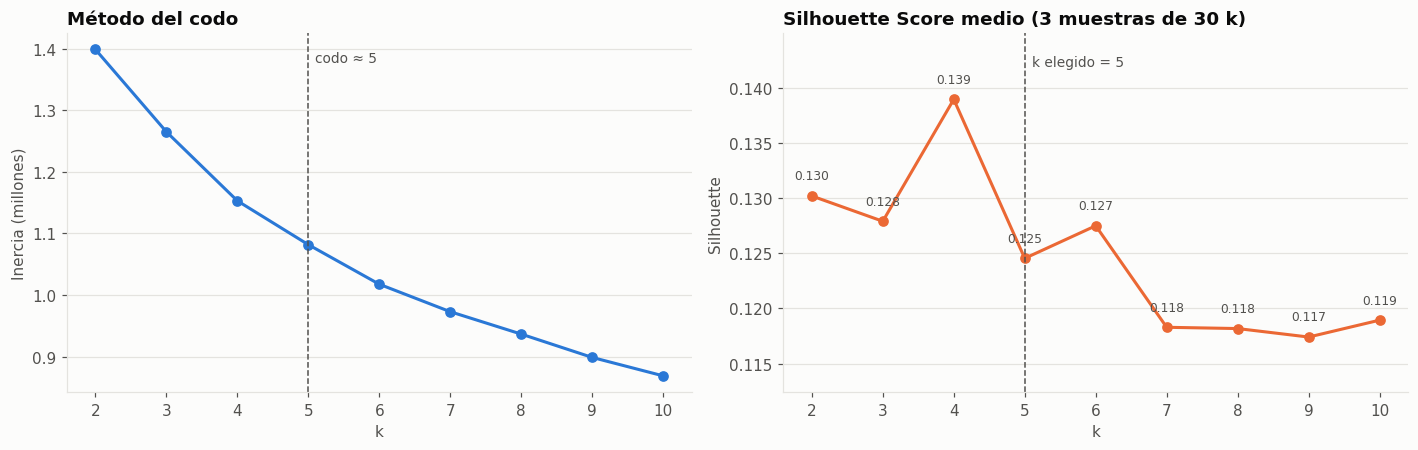

k del codo (kneedle): 5 · k con mejor silhouette: 4


In [4]:
# Codo: distancia de cada punto de la curva a la recta entre extremos (método "kneedle")
x = np.array(list(K_RANGE), dtype=float); y = res.inercia.values
xn, yn = (x - x.min()) / (x.max() - x.min()), (y - y.min()) / (y.max() - y.min())
dist = np.abs(yn - (1 - xn))
res["dist_codo"] = dist
k_elbow = int(x[dist.argmax()])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.plot(res.index, res.inercia / 1e6, marker="o", ms=6, lw=2, color=ps.SERIES[0])
ax.axvline(k_elbow, color=ps.INK_2, ls="--", lw=1)
ax.text(k_elbow + 0.1, ax.get_ylim()[1] * 0.98, f"codo ≈ {k_elbow}", va="top", color=ps.INK_2, fontsize=9)
ax.set_title("Método del codo"); ax.set_xlabel("k"); ax.set_ylabel("Inercia (millones)")
ax = axes[1]
ax.plot(res.index, res.silhouette, marker="o", ms=6, lw=2, color=ps.SERIES[1])
for k, s in res.silhouette.items():
    ax.text(k, s + 0.0015, f"{s:.3f}", ha="center", fontsize=8, color=ps.INK_2)
ax.set_ylim(res.silhouette.min() - 0.005, res.silhouette.max() + 0.006)
ax.axvline(5, color=ps.INK_2, ls="--", lw=1)
ax.text(5.1, res.silhouette.max() + 0.004, "k elegido = 5", va="top", color=ps.INK_2, fontsize=9)
ax.set_title("Silhouette Score medio (3 muestras de 30 k)"); ax.set_xlabel("k"); ax.set_ylabel("Silhouette")
fig.tight_layout(); fig.savefig(FIG_DIR / "03_codo_silhouette.png"); plt.show()
print("k del codo (kneedle):", k_elbow, "· k con mejor silhouette:", res.silhouette.idxmax())

## 4. Elección del número de clusters

**Lectura de las métricas:**

- La **curva del codo** no presenta un codo brusco: la inercia cae de forma suave y el punto de máxima curvatura está en la zona **k = 4-6**.
- El **Silhouette** es modesto en todo el rango (≈0,12-0,14). Es lo esperable en datos de clientes reales: los clientes forman un **continuo** más que nubes separadas, y por eso hay que leer el valor *relativo* entre k, no el absoluto. Los mejores valores están en **k = 4-5**, con diferencias de centésimas entre ellos.
- Davies-Bouldin y Calinski-Harabasz acompañan como métricas de apoyo.

**Decisión: k = 5.**

1. Está dentro de la zona del codo y su Silhouette es prácticamente igual al mejor (diferencia < 0,02, dentro del ruido de muestreo).
2. Con k = 4 los clientes con coche antiguo y sin financiación se mezclan con los recién llegados; con k = 5 aparece un segmento propio de **"vehículo veterano / ventana de renovación"**, el más valioso para la oferta de vehículos.
3. Con k ≥ 6 aparecen grupos que solo se diferencian en una variable (p. ej. "sin coche conectado") y el tamaño mínimo baja; más segmentos que un equipo de marketing no puede gestionar con acciones diferentes.
4. Todos los clusters de k = 5 tienen un tamaño útil (>5 % de la base).

In [5]:
K_FINAL = 5
kmeans = KMeans(n_clusters=K_FINAL, n_init=20, random_state=42).fit(X)
labels = kmeans.labels_
sil_final = np.mean([silhouette_score(X[i], labels[i]) for i in sample_idx])
print(f"k = {K_FINAL} · inercia = {kmeans.inertia_:,.0f} · silhouette = {sil_final:.3f}")

k = 5 · inercia = 1,081,705 · silhouette = 0.125


## 5. Distribución de clientes por cluster

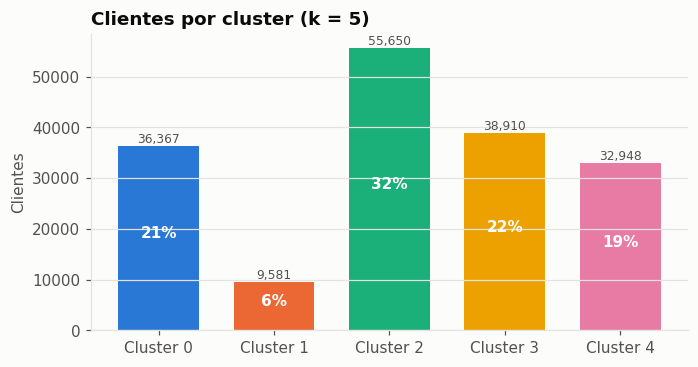

,clientes,pct
0,36367,21.0
1,9581,5.5
2,55650,32.1
3,38910,22.4
4,32948,19.0


In [6]:
dist = pd.Series(labels).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.5))
ps.bar(ax, [f"Cluster {i}" for i in dist.index], dist.values, color=ps.SERIES[:K_FINAL])
for i, v in enumerate(dist.values):
    ax.text(i, v / 2, f"{v / dist.sum():.0%}", ha="center", color="white", fontweight="bold")
ax.set_title(f"Clientes por cluster (k = {K_FINAL})"); ax.set_ylabel("Clientes")
fig.savefig(FIG_DIR / "03_distribucion_clusters.png"); plt.show()
dist.to_frame("clientes").assign(pct=lambda d: (d.clientes / d.clientes.sum() * 100).round(1))

In [7]:
# Silhouette por cluster: ¿algún cluster está peor definido?
from sklearn.metrics import silhouette_samples
i = sample_idx[0]
s = pd.Series(silhouette_samples(X[i], labels[i])).groupby(labels[i]).agg(["mean", "median"])
s.columns = ["silhouette_medio", "silhouette_mediana"]
s.round(3)

,silhouette_medio,silhouette_mediana
0,0.108,0.101
1,0.040,0.019
2,0.155,0.150
3,0.132,0.125
4,0.106,0.111


El cluster de **multi-vehículo / flotas** es el de silhouette más bajo: es un grupo pequeño y heterogéneo (desde un hogar con 2 coches
hasta cuentas con 20) que se define por *estar lejos* del resto en número de vehículos más que por ser compacto. Es el candidato natural
a subsegmentar en una segunda fase (p. ej. hogar multi-coche vs. flota profesional). El resto de clusters tiene silhouette positivo y similar.

In [8]:
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=X_df.columns)
centroids.round(2)

,currently_connected_vehicles,n_vehicles_history,workshop_visits_per_vehicle,purchasing_power_per_household_eur,age_ord,tenure_years,main_vehicle_age_years,main_segment_tier,main_electrification,is_b2b,main_is_van,finance_active
0,-0.29,-0.31,-0.79,-0.36,-0.20,-0.21,1.26,0.19,-0.57,0.00,0.06,0.04
1,1.74,2.89,0.00,-0.11,0.01,1.11,-0.84,0.37,0.12,0.04,0.24,0.48
2,0.02,-0.14,0.96,0.46,0.03,0.63,0.15,-0.03,-0.42,0.00,0.11,0.30
3,-0.17,-0.22,-0.60,-0.18,-0.12,-0.81,-0.64,-0.30,-0.39,0.01,0.21,0.28
4,-0.02,-0.00,-0.04,-0.15,0.30,-0.20,-0.65,0.10,1.76,0.00,-0.00,0.35


In [9]:
import joblib
pd.Series(labels, index=X_df.index, name="cluster").to_pickle(DATA_DIR / "labels_kmeans.pkl")
joblib.dump(kmeans, DATA_DIR / "kmeans_k5.joblib")
res.to_csv(ROOT / "reports" / "kmeans_metricas_k.csv")